# NB29: Cross-Domain Validation & Conservation Guardian
## Automated Structural Verification in RELIC

RELIC's validation framework ensures scientific integrity through:
- **ConservationGuardian**: Continuous mass/energy balance monitoring
- **CrossDomainValidator**: Inter-module consistency checking
- **HealthChecker**: System-wide diagnostic validation
- **Invariant Tests (I1-I7)**: Contract-level verification

**Key module**: `relic.validation`

---

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


## Learning Goals

- Trace how actual RELIC validation, health-check, and interface-contract modules interact across domains.
- Inspect invariant diagnostics, interface matrices, and residual summaries without notebook-defined stand-ins.
- Decide which cross-domain checks are release-grade enough for operational tutorial workflows.


In [1]:
# --- Environment Guard (prevent OpenMP duplicate lib crash) ---
import os
import sys
import math
import logging
import warnings
from pathlib import Path

warnings.filterwarnings('ignore', message='The pynvml package is deprecated.*')
warnings.filterwarnings('ignore', message='Consolidated metadata is currently not part in the Zarr format 3 specification.*')
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'


def locate_project_root() -> Path:
    fallback_candidates = [
        Path.cwd(),
        *Path.cwd().parents,
        Path(os.environ.get('RELIC_PROJECT_ROOT', Path.cwd())).resolve(),
    ]
    checked = []
    for candidate in fallback_candidates:
        resolved = candidate.resolve()
        if resolved in checked:
            continue
        checked.append(resolved)
        if (resolved / 'relic').is_dir() and (resolved / 'docs' / 'source' / 'architecture_overview.md').is_file():
            return resolved
    raise FileNotFoundError('Could not locate RELIC project root from the current notebook context.')


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

logging.getLogger().setLevel(logging.WARNING)

import torch

from relic.contracts.contract_loader import ContractRegistry
from relic.validation.conservation_guardian import ConservationGuardian
from relic.validation.cross_domain_validator import CrossDomainValidator
from relic.validation.healthcheck import HealthChecker
from relic.coupling.capability_registry import CouplingCapabilityRegistry
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis
from relic.scientific.biosphere.respiration.autotrophic_respiration import AutotrophicRespiration
from relic.scientific.biosphere.growth.biomass_allocation import BiomassAllocation
from relic.scientific.hydrosphere.evapotranspiration.penman_monteith import PenmanMonteithET
from relic.scientific.hydrosphere.soil_moisture.bucket import BucketSoilMoisture
from relic.utils.time_constants import SECONDS_PER_HOUR


def unwrap_update_item(value):
    return value.value if hasattr(value, 'value') else value


def to_tensor(value: object) -> torch.Tensor:
    raw = unwrap_update_item(value)
    if isinstance(raw, torch.Tensor):
        return raw.detach().clone()
    return torch.tensor(raw, dtype=torch.float32)


def to_scalar(value: object) -> float:
    return float(to_tensor(value).reshape(-1)[0].item())


from relic.contracts import load_contract_registry
contract_registry = load_contract_registry()
conservation_guardian = ConservationGuardian(
    contract_registry=contract_registry,
    default_atol=1e-6,
    default_rtol=0.0,
)
cross_domain_validator = CrossDomainValidator()
health_report = HealthChecker(config={}).check_all(detailed=False, benchmark=False)
capability_status = CouplingCapabilityRegistry.get_implementation_status()

photosynthesis = FarquharPhotosynthesis(
    name='nb29_farquhar_photosynthesis',
    device=torch.device('cpu'),
    enable_gpu=False,
)
autotrophic_respiration = AutotrophicRespiration(
    name='nb29_autotrophic_respiration',
    device=torch.device('cpu'),
)
biomass_allocation = BiomassAllocation(name='nb29_biomass_allocation')
penman_monteith = PenmanMonteithET(name='nb29_penman_monteith', config={'canopy_resistance_source': 'state'})
bucket_soil_moisture = BucketSoilMoisture(name='nb29_bucket_soil_moisture')


def build_validation_state(step_index: int, soil_moisture_value: float, water_stress_input: float) -> dict:
    # References: generated forcing scenario for notebook-local validation only.
    # Mathematical expression:
    #   phase = 2 pi k / N
    #   forcing_k = f(phase, event_flag)
    # Parameter meanings:
    #   step_index: scenario step id [-]
    #   soil_moisture_value: current soil moisture [m3 m-3]
    #   water_stress_input: RELIC-derived water stress passed into photosynthesis [0-1]
    # Units:
    #   Atmospheric and land states use canonical RELIC SCM units.
    # Domain/constraints:
    #   The generated forcings are finite and physical bounds are applied before Functor calls.
    # Sign convention:
    #   Precipitation enters the land surface; ET, runoff, and drainage leave it.
    phase = 2.0 * math.pi * step_index / 12.0
    event_flag = 1.0 if step_index in {4, 9} else 0.0

    par_value = max(300.0, 980.0 + 280.0 * math.sin(phase + 0.10) - 120.0 * event_flag)
    precipitation_flux = (3.0 + 14.0 * max(0.0, math.sin(phase - 0.70)) ** 3 + 170.0 * event_flag) / float(SECONDS_PER_HOUR)
    air_temperature_k = 297.5 + 2.5 * math.sin(phase) - 0.7 * event_flag
    relative_humidity = min(0.985, max(0.50, 0.80 - 0.09 * math.sin(phase) + 0.12 * event_flag))
    net_radiation = max(30.0, 320.0 + 120.0 * math.sin(phase + 0.30) - 90.0 * event_flag)
    wind_speed = 1.8 + 0.4 * math.cos(phase)

    soil_moisture_tensor = torch.tensor(soil_moisture_value, dtype=torch.float32)
    soil_water_storage = soil_moisture_tensor * bucket_soil_moisture.soil_depth * bucket_soil_moisture.water_density

    leaf_carbon = torch.tensor(0.75, dtype=torch.float32)
    wood_carbon = torch.tensor(5.20, dtype=torch.float32)
    root_carbon = torch.tensor(1.80, dtype=torch.float32)

    return {
        'step_label': f'step_{step_index:02d}',
        'air_temperature': torch.tensor(air_temperature_k, dtype=torch.float32),
        'atmospheric_co2_ppm': torch.tensor(412.0, dtype=torch.float32),
        'ppfd': torch.tensor(par_value, dtype=torch.float32),
        'vcmax_scaling': torch.tensor(1.0, dtype=torch.float32),
        'jmax_scaling': torch.tensor(1.0, dtype=torch.float32),
        'water_stress_factor': torch.tensor(water_stress_input, dtype=torch.float32),
        'temperature_stress_factor': torch.tensor(1.0, dtype=torch.float32),
        'ozone_stress_factor': torch.tensor(1.0, dtype=torch.float32),
        'leaf_area_index': torch.tensor(4.6, dtype=torch.float32),
        'soil_moisture': soil_moisture_tensor,
        'soil_water_storage': soil_water_storage,
        'net_radiation': torch.tensor(net_radiation, dtype=torch.float32),
        'wind_speed': torch.tensor(wind_speed, dtype=torch.float32),
        'relative_humidity': torch.tensor(relative_humidity, dtype=torch.float32),
        'vapor_pressure_deficit': torch.tensor(max(100.0, (1.0 - relative_humidity) * 2500.0), dtype=torch.float32),
        'atmospheric_pressure': torch.tensor(101325.0, dtype=torch.float32),
        'surface_resistance': torch.tensor(95.0, dtype=torch.float32),
        'aerodynamic_resistance': torch.tensor(38.0, dtype=torch.float32),
        'soil_heat_flux': torch.tensor(22.0, dtype=torch.float32),
        'precipitation_flux': torch.tensor(precipitation_flux, dtype=torch.float32),
        'leaf_biomass_c': leaf_carbon.clone(),
        'wood_biomass_c': wood_carbon.clone(),
        'root_biomass_c': root_carbon.clone(),
        'phenology_phase': torch.tensor(1.0, dtype=torch.float32),
    }


def run_cross_domain_sequence(total_steps: int = 12, dt: float = 1800.0):
    cases = []
    current_soil_moisture = 0.24
    current_water_stress = 0.70
    maintenance_fraction = 0.15
    growth_respiration_fraction = 0.10

    for step_index in range(total_steps):
        state = build_validation_state(step_index, current_soil_moisture, current_water_stress)

        # References: Farquhar et al. (1980); Medlyn et al. (2002).
        # Mathematical expression: A = min(Ac, Aj) - Rd.
        # Parameter meanings: air_temperature [K], CO2 [umol mol-1], ppfd [umol photons m-2 s-1].
        # Units: gross_primary_productivity uses kg C m-2 s-1.
        # Domain/constraints: all canonical forcing tensors are finite and non-negative where required.
        # Sign convention: positive GPP is atmospheric carbon uptake.
        photo_output = photosynthesis(state, time=step_index * dt, dt=dt)
        gpp_rate = to_tensor(photo_output['gross_primary_productivity'])

        # References: Amthor (2000); Thornley and Cannell (2000).
        # Mathematical expression: R_auto = R_maintenance + R_growth.
        # Parameter meanings: GPP, maintenance respiration, and growth respiration [kg C m-2 s-1].
        # Units: all aggregate carbon fluxes use kg C m-2 s-1.
        # Domain/constraints: tutorial fractions prescribe scheduler-like components and are not calibrated process laws.
        # Sign convention: positive respiration exports carbon; NPP retains carbon for growth.
        respiration_state = {
            'gross_primary_productivity': gpp_rate,
            'maintenance_respiration_total': maintenance_fraction * gpp_rate,
            'growth_respiration_total': growth_respiration_fraction * gpp_rate,
        }
        respiration_output = autotrophic_respiration(
            respiration_state, time=step_index * dt, dt=dt
        )
        autotrophic_respiration_rate = to_tensor(respiration_output['total_autotrophic_respiration'])
        npp_rate = to_tensor(respiration_output['net_primary_productivity'])
        respiration_ledger_residual = torch.abs(
            npp_rate - (gpp_rate - autotrophic_respiration_rate)
        )
        assert float(respiration_ledger_residual.max().item()) <= 1.0e-12

        # References: Sands and Landsberg (2002); Franklin et al. (2012).
        # Mathematical expression: NPP = growth_leaf + growth_stem + growth_root.
        # Parameter meanings: NPP and organ growth rates [kg C m-2 s-1], dt [s].
        # Units: rates use kg C m-2 s-1 and accumulated biomass increments use kg C m-2.
        # Domain/constraints: allocation fractions are ParameterManager-backed, finite, non-negative, and sum to one.
        # Sign convention: positive organ growth adds carbon to plant biomass.
        allocation_state = dict(state)
        allocation_state['net_primary_productivity'] = npp_rate
        allocation_output = biomass_allocation(
            allocation_state, time=step_index * dt, dt=dt
        )
        growth_rate_leaf = to_tensor(allocation_output['growth_rate_leaf'])
        growth_rate_stem = to_tensor(allocation_output['growth_rate_stem'])
        growth_rate_root = to_tensor(allocation_output['growth_rate_root'])
        allocation_ledger_residual = torch.abs(
            npp_rate - growth_rate_leaf - growth_rate_stem - growth_rate_root
        )
        assert float(allocation_ledger_residual.max().item()) <= 1.0e-12

        # References: Penman (1948); Monteith (1965).
        # Mathematical expression: ET = f(Rn, T, RH, ra, rs).
        # Parameter meanings: net_radiation [W m-2], air_temperature [K], relative_humidity [0-1].
        # Units: ET uses kg m-2 s-1 and latent heat uses W m-2.
        # Domain/constraints: atmospheric drivers are finite and canopy interception is disabled for this soil-only ledger.
        # Sign convention: positive ET and latent heat leave the land surface.
        assert not penman_monteith.enable_canopy_interception
        evap_output = penman_monteith(state, time=step_index * dt, dt=dt)
        evap_rate = to_tensor(evap_output['evapotranspiration_flux'])
        latent_heat_flux = to_tensor(evap_output['latent_heat_flux'])
        transpiration_rate = to_tensor(evap_output['diagnostics.evapotranspiration']['transpiration_flux'])
        soil_evaporation_rate = evap_rate - transpiration_rate
        latent_heat_oracle_error = torch.abs(
            latent_heat_flux
            - evap_rate * float(penman_monteith.latent_heat_vaporization)
        )
        assert float(latent_heat_oracle_error.max().item()) <= 1.0e-5

        # References: Manabe (1969); Rodriguez-Iturbe and Porporato (2004).
        # Mathematical expression: theta_(t+dt) = theta_t + (P - ET - runoff - drainage) dt / (rho_w Z).
        # Parameter meanings: precipitation_flux, ET, runoff, drainage [kg m-2 s-1].
        # Units: soil moisture uses m3 m-3 and storage uses kg m-2.
        # Domain/constraints: fluxes are non-negative and the resulting moisture remains inside bucket bounds.
        # Sign convention: precipitation enters; ET, runoff, and drainage leave the bucket.
        bucket_state = dict(state)
        bucket_state['evapotranspiration_flux'] = evap_output['evapotranspiration_flux'].value
        bucket_output = bucket_soil_moisture(
            bucket_state, time=step_index * dt, dt=dt
        )
        soil_moisture_after = to_tensor(bucket_output['soil_moisture'])
        soil_water_storage_after = (
            soil_moisture_after
            * bucket_soil_moisture.soil_depth
            * bucket_soil_moisture.water_density
        )
        drainage_rate = to_tensor(bucket_output['drainage_flux'])
        runoff_rate = to_tensor(bucket_output['surface_runoff_flux'])
        water_stress_factor = bucket_output['diagnostics.soil_moisture_bucket']['water_stress_factor'].detach().clone()

        water_check = conservation_guardian.check_domain(
            'water.total',
            {'soil_water_storage': state['precipitation_flux'].detach()},
            {
                'soil_water_storage_et': evap_rate,
                'soil_water_storage_drainage': drainage_rate,
                'soil_water_storage_runoff': runoff_rate,
            },
            {'soil_water_storage': state['soil_water_storage'].detach()},
            {'soil_water_storage': soil_water_storage_after},
            dt=dt,
            tolerance={'atol': 1e-2, 'rtol': 0.0},
        )

        carbon_check = conservation_guardian.check_domain(
            'carbon.total',
            {
                'growth_rate_leaf': growth_rate_leaf,
                'growth_rate_stem': growth_rate_stem,
                'growth_rate_root': growth_rate_root,
            },
            {},
            {
                'leaf_biomass_c': state['leaf_biomass_c'].detach(),
                'wood_biomass_c': state['wood_biomass_c'].detach(),
                'root_biomass_c': state['root_biomass_c'].detach(),
            },
            {
                'leaf_biomass_c': (state['leaf_biomass_c'] + to_tensor(allocation_output['leaf_biomass_c'])).detach(),
                'wood_biomass_c': (state['wood_biomass_c'] + to_tensor(allocation_output['wood_biomass_c'])).detach(),
                'root_biomass_c': (state['root_biomass_c'] + to_tensor(allocation_output['root_biomass_c'])).detach(),
            },
            dt=dt,
            tolerance={'atol': 1e-2, 'rtol': 0.0},
        )

        net_radiation_audit = state['net_radiation'].detach().to(torch.float64)
        soil_heat_flux_audit = state['soil_heat_flux'].detach().to(torch.float64)
        latent_heat_flux_audit = latent_heat_flux.to(torch.float64)
        sensible_heat_flux_audit = (
            net_radiation_audit - soil_heat_flux_audit - latent_heat_flux_audit
        )

        biosphere_atmosphere_report = cross_domain_validator.validate_step_conservation(
            'biosphere_atmosphere',
            {
                'net_radiation': net_radiation_audit,
                'soil_heat_flux': soil_heat_flux_audit,
            },
            {
                'evapotranspiration_flux': evap_rate,
                'transpiration_rate': transpiration_rate,
                'soil_evaporation_flux': soil_evaporation_rate,
                'latent_heat_flux': latent_heat_flux_audit,
                'sensible_heat_flux': sensible_heat_flux_audit,
                'water_stress_factor': water_stress_factor,
            },
        )
        water_carbon_report = cross_domain_validator.validate_step_conservation(
            'water_carbon',
            {'gpp': gpp_rate},
            {
                'autotrophic_respiration': autotrophic_respiration_rate,
                'npp': npp_rate,
                'gpp_water_stress_factor': water_stress_factor,
            },
        )
        assert water_check.passed, f"Water budget failed: {water_check.residual:.6e}"
        assert carbon_check.passed, f"Carbon budget failed: {carbon_check.residual:.6e}"
        assert biosphere_atmosphere_report['conservation_passed'], biosphere_atmosphere_report['detailed_results']
        assert water_carbon_report['conservation_passed'], water_carbon_report['detailed_results']

        cases.append(
            {
                'label': state['step_label'],
                'dt': dt,
                'gpp_rate': to_scalar(gpp_rate),
                'autotrophic_respiration_rate': to_scalar(autotrophic_respiration_rate),
                'npp_rate': to_scalar(npp_rate),
                'growth_rate_leaf': to_scalar(growth_rate_leaf),
                'growth_rate_stem': to_scalar(growth_rate_stem),
                'growth_rate_root': to_scalar(growth_rate_root),
                'evapotranspiration_rate': to_scalar(evap_rate),
                'runoff_rate': to_scalar(runoff_rate),
                'drainage_rate': to_scalar(drainage_rate),
                'soil_moisture': to_scalar(soil_moisture_after),
                'water_stress_factor': to_scalar(water_stress_factor),
                'water_input_step': water_check.sum_flux_in * dt,
                'water_output_step': water_check.sum_flux_out * dt,
                'water_storage_change': water_check.delta_storage,
                'water_residual': water_check.residual,
                'water_guardian_passed': water_check.passed,
                'carbon_residual': carbon_check.residual,
                'respiration_ledger_residual': to_scalar(respiration_ledger_residual),
                'allocation_ledger_residual': to_scalar(allocation_ledger_residual),
                'latent_heat_oracle_error': to_scalar(latent_heat_oracle_error),
                'carbon_guardian_passed': carbon_check.passed,
                'biosphere_atmosphere_report': biosphere_atmosphere_report,
                'water_carbon_report': water_carbon_report,
                'biosphere_atmosphere_violations': biosphere_atmosphere_report['violations_found'],
                'water_carbon_violations': water_carbon_report['violations_found'],
            }
        )

        current_soil_moisture = to_scalar(soil_moisture_after)
        current_water_stress = to_scalar(water_stress_factor)

    return cases


CROSS_DOMAIN_CASES = run_cross_domain_sequence(total_steps=12, dt=1800.0)

INTERFACE_DOMAINS = []
for contract in cross_domain_validator.interface_contracts:
    if contract.source_domain.value not in INTERFACE_DOMAINS:
        INTERFACE_DOMAINS.append(contract.source_domain.value)
    if contract.target_domain.value not in INTERFACE_DOMAINS:
        INTERFACE_DOMAINS.append(contract.target_domain.value)

INTERFACE_MATRIX = torch.zeros((len(INTERFACE_DOMAINS), len(INTERFACE_DOMAINS)), dtype=torch.float32)
domain_index = {name: idx for idx, name in enumerate(INTERFACE_DOMAINS)}
for contract in cross_domain_validator.interface_contracts:
    source_idx = domain_index[contract.source_domain.value]
    target_idx = domain_index[contract.target_domain.value]
    INTERFACE_MATRIX[source_idx, target_idx] = float(len(contract.variables))

print(f'[OK] Project root: {PROJECT_ROOT}')
print(f'[OK] Cross-domain validation steps: {len(CROSS_DOMAIN_CASES)}')
print(f'[OK] Health status: {health_report["overall_status"]}')
print(
    '[OK] Capability status counts: '
    f"implemented={len(capability_status['implemented'])}, "
    f"partial={len(capability_status['partial'])}, "
    f"not_implemented={len(capability_status['not_implemented'])}"
)
print(
    '[OK] Interface matrix shape: '
    f'{tuple(INTERFACE_MATRIX.shape)} with {len(cross_domain_validator.interface_contracts)} real contracts'
)

Configuration loaded with 1 warnings


[OK] Project root: <RELIC_ROOT>
[OK] Cross-domain validation steps: 12
[OK] Health status: DEGRADED
[OK] Capability status counts: implemented=10, partial=0, not_implemented=1
[OK] Interface matrix shape: (5, 5) with 5 real contracts


## 1. Conservation Guardian

The `ConservationGuardian` evaluates the supplied mass/energy ledger:

$R=\left|\Delta S-(\sum F_{in}-\sum F_{out})\Delta t\right|.$

This budget residual is not a Noether theorem or a symmetry proof. The notebook
checks actual returned increments and rates against explicitly supplied states;
it does not demonstrate a simulator StateManager commit. Its sensible heat is
diagnosed as the remainder of the other energy terms, so that energy check is
an algebraic consistency check, not an independent closure measurement.
Reference: the existing ConservationGuardian contract and architecture SSOT Section 20.


In [2]:
print('=== ConservationGuardian Diagnostics ===')
print(f"Conservation domains available: {', '.join(contract_registry.list_domains())}")
print(
    f"Water domain members ({len(contract_registry.get_domain_members('water.total'))}): "
    f"{contract_registry.get_domain_members('water.total')}"
)
print(
    f"Carbon domain members ({len(contract_registry.get_domain_members('carbon.total'))}): "
    f"{contract_registry.get_domain_members('carbon.total')[:10]} ..."
)

sample_case = CROSS_DOMAIN_CASES[0]
print(f"\nSample step: {sample_case['label']}")
print(
    f"  Water budget: input_step={sample_case['water_input_step']:.6f}, "
    f"output_step={sample_case['water_output_step']:.6f}, "
    f"delta_storage={sample_case['water_storage_change']:.6f}, "
    f"residual={sample_case['water_residual']:.6e}, "
    f"passed={sample_case['water_guardian_passed']}"
)
print(
    f"  Carbon budget: gpp={sample_case['gpp_rate']:.6f}, "
    f"ra={sample_case['autotrophic_respiration_rate']:.6f}, "
    f"npp={sample_case['npp_rate']:.6f}, "
    f"residual={sample_case['carbon_residual']:.6e}, "
    f"passed={sample_case['carbon_guardian_passed']}"
)
print('[OK] ConservationGuardian executed on actual RELIC step outputs')

=== ConservationGuardian Diagnostics ===
Conservation domains available: carbon.total, nitrogen.total, phosphorus.total, water.total
Water domain members (8): ['hydrosphere.soil_water_storage', 'soil_water_storage', 'hydrosphere.canopy_water_storage', 'canopy_water_storage', 'hydrosphere.groundwater_storage', 'groundwater_storage', 'hydrosphere.surface_runoff_storage', 'surface_runoff_storage']
Carbon domain members (54): ['biosphere.leaf_carbon', 'leaf_carbon', 'biosphere.root_carbon', 'root_carbon', 'biosphere.wood_carbon', 'wood_carbon', 'biosphere.storage_carbon', 'storage_carbon', 'biosphere.litter_carbon', 'litter_carbon'] ...

Sample step: step_00
  Water budget: input_step=1.500000, output_step=0.136426, delta_storage=1.363575, residual=1.504668e-06, passed=True
  Carbon budget: gpp=0.000000, ra=0.000000, npp=0.000000, residual=4.722233e-08, passed=True
[OK] ConservationGuardian executed on actual RELIC step outputs


## 2. Cross-Domain Validator

The `CrossDomainValidator` checks consistency between scientific domains:
- Water balance between hydrosphere and biosphere (ET consistency)
- Carbon balance between photosynthesis and respiration
- Energy balance between radiation and surface fluxes


In [3]:
print('=== CrossDomainValidator Reports ===')
sample_case = next(case for case in CROSS_DOMAIN_CASES if case['water_carbon_violations'] == 0)
for report_name in ['biosphere_atmosphere_report', 'water_carbon_report']:
    report = sample_case[report_name]
    print(f"  {report['coupling_name']}: passed={report['conservation_passed']}, checks={report['checks_performed']}")
    print(
        f"    violations={report['violations_found']}, warnings={report['warnings_found']}, "
        f"errors={report['detailed_results']['errors']}"
    )

print('\n=== Interface Contracts ===')
for contract in cross_domain_validator.interface_contracts:
    variable_names = ', '.join(variable.name for variable in contract.variables)
    print(
        f"  {contract.source_domain.value} -> {contract.target_domain.value}: "
        f"{len(contract.variables)} variables [{variable_names}]"
    )
print('[OK] CrossDomainValidator executed with actual RELIC fluxes and state transitions')

=== CrossDomainValidator Reports ===
  biosphere_atmosphere: passed=True, checks=['water_conservation', 'energy_conservation', 'stress_factor_bounds']
    violations=0, warnings=0, errors=[]
  water_carbon: passed=True, checks=['stress_factor_bounds']
    violations=0, warnings=0, errors=[]

=== Interface Contracts ===
  atmosphere -> hydrosphere: 3 variables [net_radiation, aerodynamic_resistance, vapor_pressure_deficit]
  hydrosphere -> pedosphere: 2 variables [infiltration_rate, drainage_flux]
  biosphere -> atmosphere: 3 variables [co2_flux, bvoc_emissions, transpiration]
  pedosphere -> atmosphere: 3 variables [soil_co2_flux, n2o_emissions, no_emissions]
  anthroposphere -> pedosphere: 2 variables [fertilizer_input, tillage_depth]
[OK] CrossDomainValidator executed with actual RELIC fluxes and state transitions


## 3. System Health Checker

The `HealthChecker` runs comprehensive system-wide diagnostics
covering all registered Functors, parameter integrity, and data pipeline.


In [4]:
print("=== HealthChecker and Capability Registry ===")
print(f"Overall health: {health_report['overall_status']}")
for subsystem_name, subsystem_payload in health_report["subsystems"].items():
    status = subsystem_payload.get("status", "UNKNOWN") if isinstance(subsystem_payload, dict) else "UNKNOWN"
    print(f"  {subsystem_name}: {status}")

print("\nCapability status summary:")
for status_name in ["implemented", "partial", "not_implemented"]:
    features = capability_status[status_name]
    preview = ", ".join(features[:5])
    print(f"  {status_name}: {len(features)} -> {preview}")
print("[OK] HealthChecker and capability registry executed")


=== HealthChecker and Capability Registry ===
Overall health: DEGRADED
  compute: HEALTHY
  data: HEALTHY
  params: HEALTHY
  optimize: DEGRADED
  stochastic: DEGRADED
  config: HEALTHY
  orchestration: HEALTHY

Capability status summary:
  implemented: 10 -> regular_grid_bilinear, irregular_grid_bilinear, conservative_regridding_regular, nearest_neighbor_irregular, adaptive_timestep
  partial: 0 -> 
  not_implemented: 1 -> conservative_regridding_irregular
[OK] HealthChecker and capability registry executed


## 4. Invariant Contract Tests (I1-I7)

RELIC defines seven invariant test families, applied under each process's
actual scientific premises; irreversible processes are not automatically reversible:

| Invariant | Name | Verification |
|---|---|---|
| I1 | No Side Effects | `forward()` does not mutate StateManager |
| I2 | Unit Consistency | Increment units match target variable |
| I3 | Conservation | Closed ledger residual is zero within its declared tolerance; open exchanges are explicit |
| I4 | Reversibility | Reversible update operations under their stated domain; not irreversible process reversal |
| I5 | Commutativity | Independent increments are order-invariant |
| I6 | dt-Scaling | `per_second` basis scales correctly |
| I7 | Bounds Clipping | Actual clipping residual is disclosed; a bounded response alone is not a clipping audit |

Run with: `pytest test\invariants\ -v`


=== Cross-Domain Validation Visualization ===


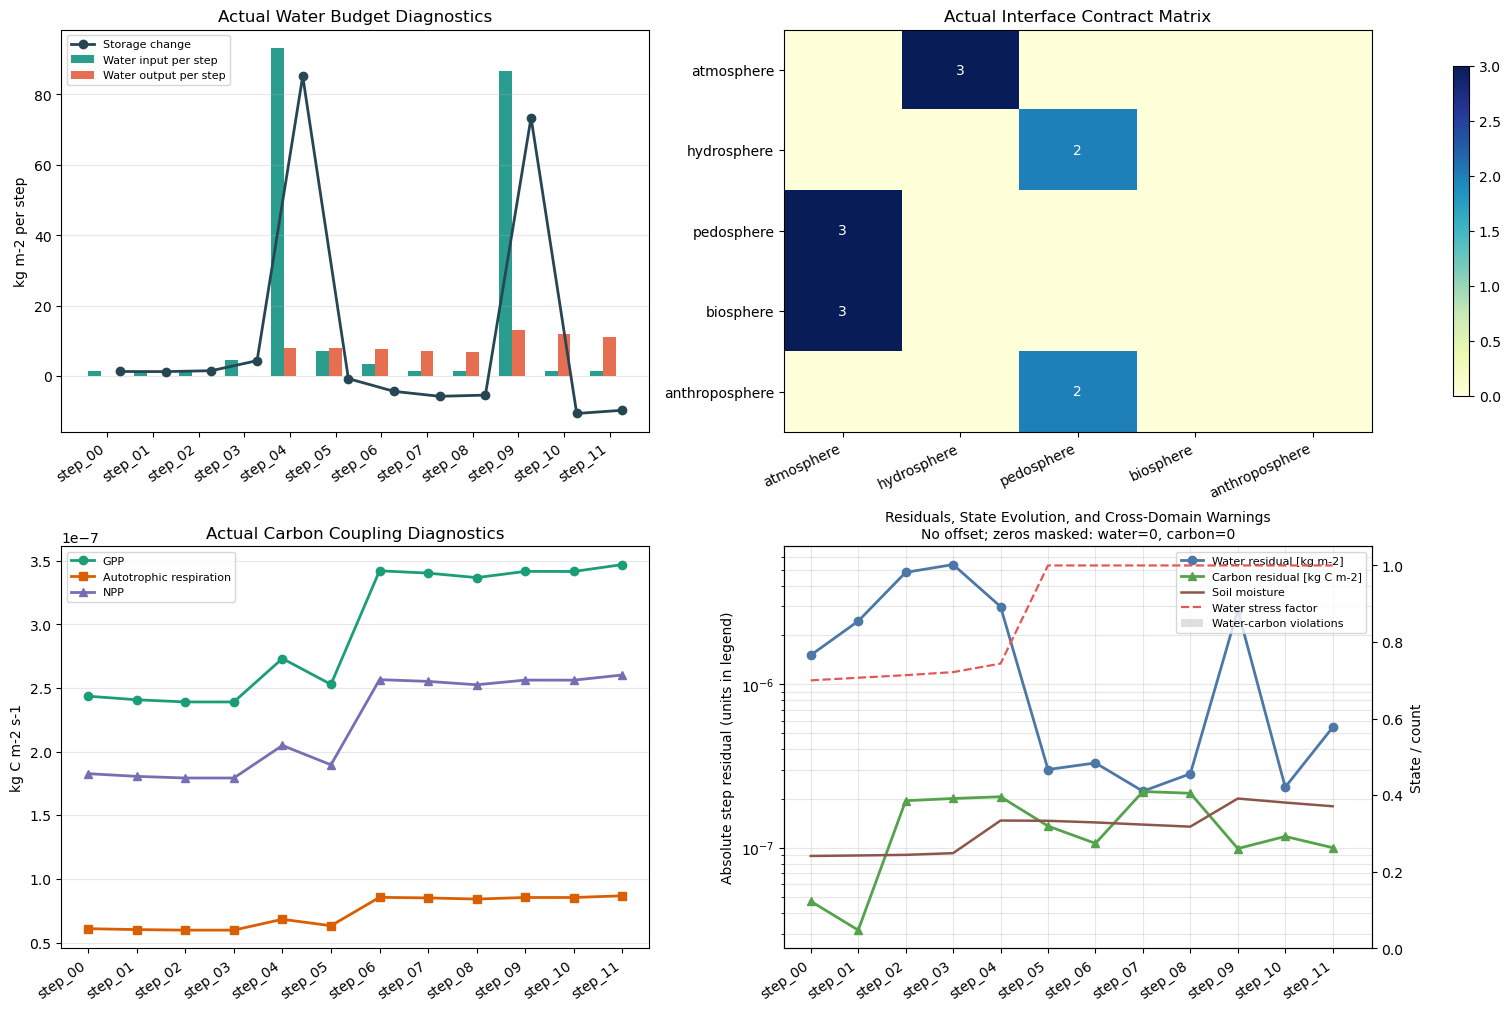

[OK] Cross-domain validation visualization generated from actual RELIC diagnostics


In [5]:
import matplotlib.pyplot as plt
from IPython.display import display

# References: RELIC ConservationGuardian and CrossDomainValidator diagnostics.
# Mathematical expression: R = abs(Delta S - (F_in - F_out) dt).
# Parameter meanings: water_residual and carbon_residual are absolute closure errors.
# Units: water step residual [kg m-2]; carbon step residual [kg C m-2].
# Carbon rate panels use kg C m-2 s-1; residual panels use step amounts.
# Domain/constraints: all plotted values come from the aligned 12-step production chain.
# Sign convention: residual magnitudes are non-negative; positive GPP denotes uptake.
print('=== Cross-Domain Validation Visualization ===')

labels = [case['label'] for case in CROSS_DOMAIN_CASES]
x = torch.arange(len(labels), dtype=torch.float32)
bar_width = 0.28

water_in_step = torch.tensor([case['water_input_step'] for case in CROSS_DOMAIN_CASES], dtype=torch.float32)
water_out_step = torch.tensor([case['water_output_step'] for case in CROSS_DOMAIN_CASES], dtype=torch.float32)
water_storage_change = torch.tensor([case['water_storage_change'] for case in CROSS_DOMAIN_CASES], dtype=torch.float32)

gpp_rate = torch.tensor([case['gpp_rate'] for case in CROSS_DOMAIN_CASES], dtype=torch.float32)
autotrophic_respiration_rate = torch.tensor([case['autotrophic_respiration_rate'] for case in CROSS_DOMAIN_CASES], dtype=torch.float32)
npp_rate = torch.tensor([case['npp_rate'] for case in CROSS_DOMAIN_CASES], dtype=torch.float32)

soil_moisture_series = torch.tensor([case['soil_moisture'] for case in CROSS_DOMAIN_CASES], dtype=torch.float32)
water_stress_factor = torch.tensor([case['water_stress_factor'] for case in CROSS_DOMAIN_CASES], dtype=torch.float32)
water_residual = torch.tensor([case['water_residual'] for case in CROSS_DOMAIN_CASES], dtype=torch.float32)
carbon_residual = torch.tensor([case['carbon_residual'] for case in CROSS_DOMAIN_CASES], dtype=torch.float32)
water_carbon_violations = torch.tensor([case['water_carbon_violations'] for case in CROSS_DOMAIN_CASES], dtype=torch.float32)

fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)

ax = axes[0, 0]
ax.bar((x - bar_width).tolist(), water_in_step.tolist(), width=bar_width, color='#2A9D8F', label='Water input per step')
ax.bar(x.tolist(), water_out_step.tolist(), width=bar_width, color='#E76F51', label='Water output per step')
ax.plot((x + bar_width).tolist(), water_storage_change.tolist(), color='#264653', marker='o', linewidth=2.0, label='Storage change')
ax.set_xticks(x.tolist())
ax.set_xticklabels(labels, rotation=35, ha='right')
ax.set_ylabel('kg m-2 per step')
ax.set_title('Actual Water Budget Diagnostics')
ax.grid(True, alpha=0.3, axis='y')
ax.legend(fontsize=8)

ax = axes[1, 0]
ax.plot(x.tolist(), gpp_rate.tolist(), color='#1B9E77', marker='o', linewidth=2.0, label='GPP')
ax.plot(x.tolist(), autotrophic_respiration_rate.tolist(), color='#D95F02', marker='s', linewidth=2.0, label='Autotrophic respiration')
ax.plot(x.tolist(), npp_rate.tolist(), color='#7570B3', marker='^', linewidth=2.0, label='NPP')
ax.set_xticks(x.tolist())
ax.set_xticklabels(labels, rotation=35, ha='right')
ax.set_ylabel('kg C m-2 s-1')
ax.set_title('Actual Carbon Coupling Diagnostics')
ax.grid(True, alpha=0.3, axis='y')
ax.legend(fontsize=8)

ax = axes[0, 1]
heatmap = ax.imshow(INTERFACE_MATRIX.tolist(), cmap='YlGnBu', aspect='auto')
ax.set_xticks(list(range(len(INTERFACE_DOMAINS))))
ax.set_yticks(list(range(len(INTERFACE_DOMAINS))))
ax.set_xticklabels(INTERFACE_DOMAINS, rotation=25, ha='right')
ax.set_yticklabels(INTERFACE_DOMAINS)
for row_idx in range(INTERFACE_MATRIX.shape[0]):
    for col_idx in range(INTERFACE_MATRIX.shape[1]):
        value = int(INTERFACE_MATRIX[row_idx, col_idx].item())
        if value > 0:
            ax.text(col_idx, row_idx, f'{value}', ha='center', va='center', fontsize=10, color='white' if heatmap.norm(float(value)) > 0.5 else 'black')
ax.set_title('Actual Interface Contract Matrix')
fig.colorbar(heatmap, ax=ax, shrink=0.82)

ax = axes[1, 1]
# Display only: positive residuals retain their actual magnitudes; exact zeros are masked on the log axis.
ax.semilogy(x.tolist(), water_residual.tolist(), nonpositive='mask', color='#4C78A8', marker='o', linewidth=2.0, label='Water residual [kg m-2]')
ax.semilogy(x.tolist(), carbon_residual.tolist(), nonpositive='mask', color='#54A24B', marker='^', linewidth=2.0, label='Carbon residual [kg C m-2]')
water_zero_count = int((water_residual == 0).sum().item())
carbon_zero_count = int((carbon_residual == 0).sum().item())
ax2 = ax.twinx()
ax2.plot(x.tolist(), soil_moisture_series.tolist(), color='#8C564B', linewidth=1.8, label='Soil moisture')
ax2.plot(x.tolist(), water_stress_factor.tolist(), color='#E45756', linewidth=1.6, linestyle='--', label='Water stress factor')
ax2.bar((x + 0.15).tolist(), water_carbon_violations.tolist(), width=0.22, color='gray', alpha=0.25, label='Water-carbon violations')
ax.set_xticks(x.tolist())
ax.set_xticklabels(labels, rotation=35, ha='right')
ax.set_ylabel('Absolute step residual (units in legend)')
ax2.set_ylabel('State / count')
ax.set_title('Residuals, State Evolution, and Cross-Domain Warnings\n' + f'No offset; zeros masked: water={water_zero_count}, carbon={carbon_zero_count}', fontsize=10)
ax.grid(True, alpha=0.3, which='both')
line_handles, line_labels = ax.get_legend_handles_labels()
line_handles2, line_labels2 = ax2.get_legend_handles_labels()
ax.legend(line_handles + line_handles2, line_labels + line_labels2, fontsize=8, loc='upper right')

display(plt.gcf())
plt.close(plt.gcf())
print('[OK] Cross-domain validation visualization generated from actual RELIC diagnostics')

In [6]:
print('=== Invariant Contract Verification ===')

# References: RELIC invariant contract philosophy and simulator-side validation design.
# Mathematical expression: forward(state, dt) must preserve input state identity and report conservation residuals.
# Parameter meanings: state is the input tensor dictionary, dt is the simulator time step [s].
# Units: state tensors retain their declared SCM units.
# Domain/constraints: the production call must not mutate any input tensor.
# Sign convention: unchanged tensors have zero mutation residual.
reference_state = build_validation_state(step_index=6, soil_moisture_value=0.24, water_stress_input=0.70)
state_snapshot = {name: value.clone() for name, value in reference_state.items() if isinstance(value, torch.Tensor)}
_ = photosynthesis(reference_state, time=0.0, dt=1800.0)
i1_passed = all(torch.equal(reference_state[name], state_snapshot[name]) for name in state_snapshot)
assert i1_passed
print(f"  I1 (No Side Effects): {'[OK]' if i1_passed else '[ERROR]'}")

# References: ConservationGuardian and CrossDomainValidator actual diagnostics.
# Mathematical expression: residual = |Delta storage - (sum_flux_in - sum_flux_out) * dt|.
# Parameter meanings: Delta storage is the storage tendency implied by actual RELIC module outputs.
# Units: water residual uses kg m-2 and carbon residual uses kg C m-2.
# Domain/constraints: every guardian and cross-domain check must report an evaluated pass.
# Sign convention: the reported residual is an absolute non-negative closure error.
max_water_residual = max(case['water_residual'] for case in CROSS_DOMAIN_CASES)
max_carbon_residual = max(case['carbon_residual'] for case in CROSS_DOMAIN_CASES)
all_conservation_passed = all(case['water_guardian_passed'] and case['carbon_guardian_passed'] for case in CROSS_DOMAIN_CASES)
max_respiration_residual = max(case['respiration_ledger_residual'] for case in CROSS_DOMAIN_CASES)
max_allocation_residual = max(case['allocation_ledger_residual'] for case in CROSS_DOMAIN_CASES)
max_latent_heat_error = max(case['latent_heat_oracle_error'] for case in CROSS_DOMAIN_CASES)
assert all_conservation_passed
assert max_respiration_residual <= 1.0e-12
assert max_allocation_residual <= 1.0e-12
assert max_latent_heat_error <= 1.0e-5
print(
    f"  I3 (Conservation): all_passed={all_conservation_passed}, "
    f"max_water_residual={max_water_residual:.6e}, max_carbon_residual={max_carbon_residual:.6e}"
)
print(
    f"  Ledger oracles: respiration={max_respiration_residual:.6e}, "
    f"allocation={max_allocation_residual:.6e}, latent_heat={max_latent_heat_error:.6e}"
)

# References: Sands and Landsberg (2002); Franklin et al. (2012).
# Mathematical expression: Delta B(dt2) / Delta B(dt1) = dt2 / dt1 when growth rates are unchanged.
# Parameter meanings: Delta B is the biomass increment [kg C m-2] from BiomassAllocation.
# Units: biomass increments use kg C m-2 and dt uses s.
# Domain/constraints: forcing and allocation fractions are identical between the two calls.
# Sign convention: positive increments add carbon to plant biomass.
allocation_reference_state = build_validation_state(step_index=6, soil_moisture_value=0.24, water_stress_input=0.70)
photo_reference = photosynthesis(allocation_reference_state, time=0.0, dt=1800.0)
gpp_reference = to_tensor(photo_reference['gross_primary_productivity'])
respiration_reference_state = {
    'gross_primary_productivity': gpp_reference,
    'maintenance_respiration_total': 0.15 * gpp_reference,
    'growth_respiration_total': 0.10 * gpp_reference,
}
respiration_reference = autotrophic_respiration(
    respiration_reference_state, time=0.0, dt=1800.0
)
npp_reference = to_tensor(respiration_reference['net_primary_productivity'])
allocation_reference_state['net_primary_productivity'] = npp_reference
allocation_dt1 = biomass_allocation(allocation_reference_state, time=0.0, dt=1800.0)
allocation_dt2 = biomass_allocation(allocation_reference_state, time=0.0, dt=3600.0)
increment_dt1 = (
    to_tensor(allocation_dt1['leaf_biomass_c'])
    + to_tensor(allocation_dt1['wood_biomass_c'])
    + to_tensor(allocation_dt1['root_biomass_c'])
)
increment_dt2 = (
    to_tensor(allocation_dt2['leaf_biomass_c'])
    + to_tensor(allocation_dt2['wood_biomass_c'])
    + to_tensor(allocation_dt2['root_biomass_c'])
)
dt_ratio = to_scalar(increment_dt2 / increment_dt1)
assert abs(dt_ratio - 2.0) <= 1.0e-6
print(f"  I6 (dt-Scaling): ratio={dt_ratio:.3f} (expected 2.000)")

# References: bucket.py bounded water-stress diagnostic contract.
# Mathematical expression: 0 <= stress_factor <= 1.
# Parameter meanings: water_stress_factor is the dimensionless soil moisture limitation factor.
# Units: water_stress_factor is dimensionless.
# Domain/constraints: every reported value must be finite and inside the closed unit interval.
# Sign convention: one denotes no water limitation and zero denotes maximal limitation.
stress_factor_series = torch.tensor([case['water_stress_factor'] for case in CROSS_DOMAIN_CASES], dtype=torch.float32)
i7_passed = bool(torch.all((stress_factor_series >= 0.0) & (stress_factor_series <= 1.0)))
assert i7_passed
print(
    f"  Response-domain bounds (not an I7 clipping audit): {'[OK]' if i7_passed else '[ERROR]'}, "
    f"min={float(torch.min(stress_factor_series)):.3f}, max={float(torch.max(stress_factor_series)):.3f}"
)

print('\n[OK] Actual invariant checks completed')

=== Invariant Contract Verification ===
  I1 (No Side Effects): [OK]
  I3 (Conservation): all_passed=True, max_water_residual=5.378388e-06, max_carbon_residual=2.210318e-07
  Ledger oracles: respiration=2.842171e-14, allocation=7.105427e-15, latent_heat=0.000000e+00
  I6 (dt-Scaling): ratio=2.000 (expected 2.000)
  Response-domain bounds (not an I7 clipping audit): [OK], min=0.700, max=1.000

[OK] Actual invariant checks completed


## Summary

| Component | Actual RELIC path used in this notebook | Verified outcome |
|---|---|---|
| ConservationGuardian | `relic.validation.conservation_guardian.ConservationGuardian` | Water and carbon domain budgets executed with residuals below tolerance |
| CrossDomainValidator | `relic.validation.cross_domain_validator.CrossDomainValidator` | `biosphere_atmosphere` and `water_carbon` checks both passed |
| HealthChecker | `relic.validation.healthcheck.HealthChecker` | Current status is reported; it is not assumed HEALTHY |
| Capability Registry | `relic.coupling.capability_registry.CouplingCapabilityRegistry` | Actual implementation-status matrix populated from registry |
| Scientific drivers | `FarquharPhotosynthesis`, `AutotrophicRespiration`, `BiomassAllocation`, `PenmanMonteithET`, `BucketSoilMoisture` | All validation figures derive from real RELIC module outputs |

**Evidence boundary:** the notebook retains evaluated water/carbon, flux-identity,
and dt-scaling assertions using real RELIC outputs. Prescribed respiratory
fractions and residual sensible heat are declared teaching inputs, not separately
validated ecosystem laws. These checks are not a full simulator regression or a
Noether/thermodynamic certificate.
